# AA3 · Parcial II · Cuaderno 2: Embeddings
**Alumno:** Edgar Ivan Galvez Ortega
**Datos:** [mteb/SpanishNewsClassification](https://huggingface.co/datasets/mteb/SpanishNewsClassification) (Hugging Face; original: [MarcOrfilaCarreras/spanish-news](https://huggingface.co/datasets/MarcOrfilaCarreras/spanish-news)), noticias en español de 12 categorías

Conjunto contra secuencia en español: una bolsa de **bigramas** (Bloque 4) contra **Embedding + Bi-LSTM** (Bloque 5), con las mismas reglas. Sale de la Práctica 4, ejercicio final, Parte 1.

## 1. Datos
### 1.1 Entorno
Instala lo que falte. Igual que en la Práctica 4: Keras usa TensorFlow en Colab y PyTorch en local; `TextVectorization` y `tf.data` necesitan TensorFlow con cualquier motor.

In [1]:
import os
import sys
import importlib.util
import subprocess

EN_COLAB = importlib.util.find_spec("google.colab") is not None

paquetes = {"datasets": "datasets", "sklearn": "scikit-learn", "tensorflow": "tensorflow", "keras": "keras",
            "torch": "torch", "pandas": "pandas", "matplotlib": "matplotlib"}
faltantes = [pip for mod, pip in paquetes.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    print(f"Instalando paquetes faltantes: {faltantes}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
else:
    print("Todas las dependencias ya están instaladas.")

# Motor de Keras ANTES de importar keras (igual que la P4)
os.environ["KERAS_BACKEND"] = "tensorflow" if EN_COLAB else "torch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import keras
import tensorflow as tf
import torch

print("--- Auditoría de Entorno ---")
print(f"Entorno: {'Google Colab' if EN_COLAB else 'Local / servidor'} · Python {sys.version.split()[0]}")
print(f"Keras {keras.__version__} · motor: {keras.backend.backend()} · TensorFlow {tf.__version__} · PyTorch {torch.__version__}")
assert int(keras.__version__.split(".")[0]) >= 3, "Se necesita Keras 3"
gpu = torch.cuda.is_available() if keras.backend.backend() == "torch" else len(tf.config.list_physical_devices("GPU")) > 0
print(f"¿El motor de Keras tiene GPU?: {gpu}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))

Instalando paquetes faltantes: ['datasets']
--- Auditoría de Entorno ---
Entorno: Local / servidor · Python 3.13.0
Keras 3.15.1 · motor: torch · TensorFlow 2.21.0 · PyTorch 2.6.0+cu124
¿El motor de Keras tiene GPU?: True (NVIDIA GeForce RTX 4070 SUPER)


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEED = 42
keras.utils.set_random_seed(SEED)
BATCH = 32

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_colwidth", 160)
print(f"NumPy {np.__version__} · pandas {pd.__version__} · semilla {SEED}")

NumPy 2.3.5 · pandas 3.0.5 · semilla 42


### 1.2 El dataset
**Fuente:** [`mteb/SpanishNewsClassification`](https://huggingface.co/datasets/mteb/SpanishNewsClassification) en Hugging Face (licencia MIT). Es la versión de MTEB del dataset [`MarcOrfilaCarreras/spanish-news`](https://huggingface.co/datasets/MarcOrfilaCarreras/spanish-news): noticias de medios españoles clasificadas en **12 categorías temáticas**. Trae un solo *split* de 2,048 noticias, así que la división la hacemos nosotros.

Se quitan los textos duplicados **antes** de dividir, para que una misma noticia no quede en entrenamiento y en prueba a la vez.

In [3]:
from datasets import load_dataset

DATASET = "mteb/SpanishNewsClassification"
df = load_dataset(DATASET, split="train").to_pandas()[["text", "label"]]
n_original = len(df)
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"].str.len() > 0].drop_duplicates(subset="text").reset_index(drop=True)
df["label"] = df["label"].astype(int)

CLASES = sorted(int(c) for c in df["label"].unique())
N_CLASES = len(CLASES)
print(f"Dataset: {DATASET}")
print(f"Ejemplos: {n_original:,} originales → {len(df):,} después de quitar vacíos y duplicados")
print(f"Clases: {N_CLASES} (etiquetas {CLASES[0]} a {CLASES[-1]})")
df["label"].value_counts().sort_index().rename("noticias").to_frame().T

c:\Users\Edgar\Documents\Edgar\Ibero\Semestre 7\Aprendizaje automatico 3\ml_gpu_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating train split: 100%|██████████| 2048/2048 [00:00<00:00, 82788.96 examples/s]

Dataset: mteb/SpanishNewsClassification
Ejemplos: 2,048 originales → 2,048 después de quitar vacíos y duplicados
Clases: 12 (etiquetas 0 a 11)


label,0,1,2,3,4,5,6,7,8,9,10,11
noticias,170,171,171,171,171,170,171,170,171,171,170,171


### 1.3 División con semilla: 70 % / 15 % / 15 %
Estratificada por clase, con `random_state = 42`. La **prueba** no se toca hasta el final y se usa **una sola vez** por modelo.

In [4]:
textos, etiquetas = df["text"].tolist(), df["label"].tolist()
x_tmp, x_test, y_tmp, y_test = train_test_split(textos, etiquetas, test_size=0.15, stratify=etiquetas, random_state=SEED)
x_train, x_val, y_train, y_val = train_test_split(x_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=SEED)
y_train, y_val, y_test = (np.array(y, dtype="int32") for y in (y_train, y_val, y_test))
print(f"Entrenamiento: {len(x_train):,} · Validación: {len(x_val):,} · Prueba: {len(x_test):,}")

Entrenamiento: 1,432 · Validación: 308 · Prueba: 308


### 1.4 ¿Qué es cada clase?
El dataset de MTEB trae las etiquetas como números, sin nombre. Para leer los resultados, a cada clase le ponemos un nombre con sus **palabras más características**: las de mayor TF-IDF promedio en esa clase comparada con las demás. Se calcula **solo con el entrenamiento**.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_nombres = TfidfVectorizer(lowercase=True, min_df=5, max_df=0.25, token_pattern=r"(?u)\b[^\W\d_]{4,}\b")
M = tfidf_nombres.fit_transform(x_train)
vocab_nombres = np.array(tfidf_nombres.get_feature_names_out())

palabras_clase, NOMBRES = {}, {}
for k in CLASES:
    diferencia = np.asarray(M[y_train == k].mean(axis=0) - M[y_train != k].mean(axis=0)).ravel()
    top = vocab_nombres[diferencia.argsort()[::-1][:6]]
    palabras_clase[k] = ", ".join(top)
    NOMBRES[k] = f"{k}·{top[0]}"

pd.DataFrame({"Nombre corto": NOMBRES, "Palabras más características (entrenamiento)": palabras_clase})

,Nombre corto,Palabras más características (entrenamiento)
0,0·cocina,"cocina, receta, recetas, salsa, cena, comida"
1,1·estrellas,"estrellas, tierra, espacial, suscriptor, nasa, solar"
2,2·euros,"euros, millones, españa, agricultores, precios, gobierno"
3,3·vestido,"vestido, moda, look, prendas, color, vestidos"
4,4·pacientes,"pacientes, arterial, tratamiento, hipertensión, enfermedad, riesgo"
5,5·defensa,"defensa, sistema, sistemas, combate, capacidades, fuerzas"
6,6·coche,"coche, motor, coches, eléctricos, mercedes, eléctrico"
7,7·película,"película, películas, espinof, series, cine, taquilla"
8,8·gobierno,"gobierno, milei, psoe, feijóo, galicia, amnistía"
9,9·iglesia,"iglesia, dios, papa, francisco, jesús, vaticano"


In [6]:
for k in CLASES[:6]:
    i = int(np.where(y_train == k)[0][0])
    print(f"[{NOMBRES[k]}] {x_train[i][:220]}...\n")

[0·cocina] Hay anuncios que irremediablemente se quedan atrapados en nuestra memoria. Son muchos los ejemplos televisivos que han acabado conservados. Bien por su jingle, como el negrito del África tropical que cultivando cantaba l...

[1·estrellas] La Academia de Ciencias de California inauguró su principal muestra fotográfica con espectaculares trabajos de fotógrafos de naturaleza, vida salvaje y ecologismo de todo el mundo.La muestra "BigPicture" exhibe el trabaj...

[2·euros] El precio del alquiler es cada vez más elevado y los inquilinos tienen cada año más difícil enfrentarse a las cuotas. Durante el mes de enero de 2024, el metro cuadrado en España se situó en los 12,4 euros, lo que supone...

[3·vestido] Hace dos días la Asociación Española de Consumidores (la OCU) lanzaba una alerta de la venta en internet de inyecciones de ácido hialurónico para ser utilizadas sin aplicación médica.  El ácido hialurónico es el único tr...

[4·pacientes] Presentación inusual de una de las comp

### 1.5 El cociente de Google y mi predicción
$$\text{cociente} = \frac{\text{muestras de entrenamiento}}{\text{mediana de palabras por muestra}}$$
Menor que 1,500 → bigramas (modelo de **conjunto**); 1,500 o más → modelo de **secuencia**.

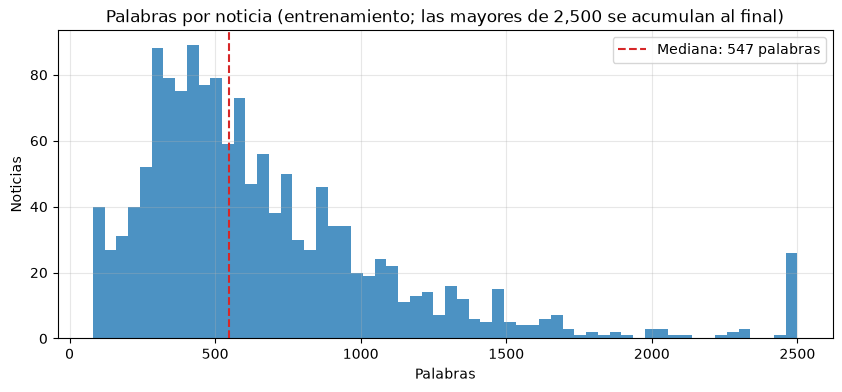

Noticias de entrenamiento: 1,432 · mediana: 547 palabras · máximo: 29,746
Cociente = 1,432 / 547 = 2.6
La regla predice: BIGRAMAS (modelo de conjunto)


In [7]:
longitudes = np.array([len(t.split()) for t in x_train])
mediana = float(np.median(longitudes))
cociente = len(x_train) / mediana

plt.figure(figsize=(10, 4))
plt.hist(np.clip(longitudes, 0, 2500), bins=60, color="tab:blue", alpha=0.8)
plt.axvline(mediana, color="tab:red", linestyle="--", label=f"Mediana: {mediana:.0f} palabras")
plt.title("Palabras por noticia (entrenamiento; las mayores de 2,500 se acumulan al final)")
plt.xlabel("Palabras")
plt.ylabel("Noticias")
plt.legend()
plt.show()

print(f"Noticias de entrenamiento: {len(x_train):,} · mediana: {mediana:.0f} palabras · máximo: {longitudes.max():,}")
print(f"Cociente = {len(x_train):,} / {mediana:.0f} = {cociente:.1f}")
print("La regla predice:", "BIGRAMAS (modelo de conjunto)" if cociente < 1500 else "MODELO DE SECUENCIA")

> **Mi predicción, escrita antes de entrenar:** **ganan los bigramas, y por mucho.** El cociente sale de un solo dígito, muy lejos de 1,500: son pocas noticias (unas 1,400 para entrenar) y muy largas (cientos de palabras), repartidas en 12 clases. Con tan pocos ejemplos por clase (~120), la Bi-LSTM no tiene datos para aprender a usar el orden de 600 tokens. Además, el tema de una noticia se nota en sus palabras ("obispo", "liga", "misil"), sin necesidad del orden. Espero que la Bi-LSTM quede muy por debajo de los bigramas.

### 1.6 Del texto al tensor
Limpieza mínima antes de vectorizar: signos de apertura y comillas del español, que la estandarización por defecto de `TextVectorization` (minúsculas y sin puntuación ASCII) no quita, y saltos de línea. Después, dos vectorizadores, cuyo vocabulario se construye **solo con el entrenamiento** (`adapt`):

| Vectorizador | Modo | Vocabulario | Cada noticia se vuelve… |
|---|---|---|---|
| `vec_bi` | `multi_hot`, `ngrams=2` | 30,000 palabras y pares de palabras | un vector de 30,000 |
| `vec_seq` | `int`, 600 tokens | 30,000 palabras | una secuencia de 600 índices |

In [8]:
def limpiar(texto):
    texto = tf.strings.regex_replace(texto, r"[¿¡«»“”‘’…—–]", " ")
    return tf.strings.regex_replace(texto, r"\s+", " ")

def a_dataset(x, y, mezclar=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if mezclar:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).map(lambda t, e: (limpiar(t), e))

train_ds = a_dataset(x_train, y_train, mezclar=True)
val_ds = a_dataset(x_val, y_val)
test_ds = a_dataset(x_test, y_test)          # sin mezclar: para emparejar predicciones con textos
textos_train = a_dataset(x_train, y_train).map(lambda x, y: x)

def crear_vectorizador(nombre, **kwargs):
    t0 = time.time()
    v = layers.TextVectorization(**kwargs)
    v.adapt(textos_train)                    # vocabulario SOLO con el entrenamiento
    print(f"{nombre:8s} listo en {time.time() - t0:4.1f} s · vocabulario: {v.vocabulary_size():,}")
    return v

def vectorizar(ds, vectorizador, cache=False):
    ds = ds.map(lambda x, y: (vectorizador(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return (ds.cache() if cache else ds).prefetch(tf.data.AUTOTUNE)

vec_bi = crear_vectorizador("vec_bi", max_tokens=30_000, output_mode="multi_hot", ngrams=2)
vec_seq = crear_vectorizador("vec_seq", max_tokens=30_000, output_mode="int", output_sequence_length=600)

train_bi, val_bi, test_bi = (vectorizar(d, vec_bi) for d in (train_ds, val_ds, test_ds))
train_seq, val_seq, test_seq = (vectorizar(d, vec_seq, cache=True) for d in (train_ds, val_ds, test_ds))

x_b, _ = next(iter(train_bi))
x_s, _ = next(iter(train_seq))
print("\nLote multi-hot de bigramas:", tuple(x_b.shape), "· Lote de secuencias:", tuple(x_s.shape))
vocab_bi = [str(t) for t in vec_bi.get_vocabulary()]
print("Algunos bigramas del vocabulario:", [t for t in vocab_bi[2:600] if " " in t][:12])
fila = np.asarray(x_s[0])
print(f"Relleno (ceros) en la 1.ª noticia del lote: {int((fila == 0).sum())} de 600 · [UNK]: {int((fila == 1).sum())}")

vec_bi   listo en  1.1 s · vocabulario: 30,000
vec_seq  listo en  0.3 s · vocabulario: 30,000

Lote multi-hot de bigramas: (32, 30000) · Lote de secuencias: (32, 600)
Algunos bigramas del vocabulario: ['de la', 'en el', 'en la', 'de los', 'a la', 'de las', 'que se', 'lo que', 'con el', 'a los', 'y la', 'que el']
Relleno (ceros) en la 1.ª noticia del lote: 0 de 600 · [UNK]: 29


## 2. Línea base
**Bolsa de bigramas** del Bloque 4: *multi-hot* de 30,000 → `Dense(16, relu)` → `Dropout(0.5)` → salida. Como hay **12 clases** y no 2, la salida pasa de `Dense(1, sigmoid)` a **`Dense(12, softmax)`** y la pérdida de `binary_crossentropy` a **`sparse_categorical_crossentropy`** (las etiquetas son enteros).

`entrenar_texto()` es la de la práctica, con las mismas reglas para los dos modelos: RMSprop, hasta 20 épocas con `EarlyStopping` (paciencia 4, restaura los mejores pesos según `val_loss`) y **una sola evaluación en prueba**, al final.

In [9]:
resultados_dict, predicciones = {}, {}

def obtener_callbacks(paciencia=4):
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1)]

def graficar_curvas(history, titulo="", metrica="accuracy"):
    entr, val = history.history[metrica], history.history[f"val_{metrica}"]
    epocas = range(1, len(entr) + 1)
    mejor = int(np.argmin(history.history["val_loss"]))
    plt.figure(figsize=(8, 4))
    plt.plot(epocas, entr, "o--", color="tab:blue", label=f"Entrenamiento ({metrica})")
    plt.plot(epocas, val, "o-", color="tab:orange", label=f"Validación ({metrica})")
    plt.axvline(mejor + 1, color="gray", linestyle=":", label=f"Mejor época (val_loss): {mejor + 1}")
    plt.title(f"Curvas de aprendizaje — {titulo}")
    plt.xlabel("Época")
    plt.ylabel(metrica)
    plt.legend()
    plt.show()

def entrenar_texto(nombre, modelo, ds_train, ds_val, ds_test, familia, epocas=20, paciencia=4):
    # Entrena, evalúa UNA sola vez en prueba y anota el resultado
    modelo.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    history = modelo.fit(ds_train, validation_data=ds_val, epochs=epocas, callbacks=obtener_callbacks(paciencia), verbose=2)
    duracion = time.time() - t0
    mejor = int(np.argmin(history.history["val_loss"]))
    probs = modelo.predict(ds_test, verbose=0)                    # única vez que se usa la prueba
    pred = probs.argmax(axis=1)
    predicciones[nombre] = probs
    resultados_dict[nombre] = {
        "Familia": familia,
        "Exactitud val": history.history["val_accuracy"][mejor],
        "Exactitud prueba": accuracy_score(y_test, pred),
        "F1 macro prueba": f1_score(y_test, pred, average="macro"),
        "Parámetros": modelo.count_params(),
        "Épocas": len(history.history["loss"]),
        "Seg/época": duracion / len(history.history["loss"]),
    }
    r = resultados_dict[nombre]
    print(f"\n{nombre}: exactitud val {r['Exactitud val']:.3f} · PRUEBA {r['Exactitud prueba']:.3f} · "
          f"F1 macro {r['F1 macro prueba']:.3f} · {r['Seg/época']:.1f} s/época")
    graficar_curvas(history, nombre)
    return history

Model: "bigramas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ multi_hot (InputLayer)          │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │       480,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           204 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,220 (1.83 MB)

 Trainable params: 480,220 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


c:\Users\Edgar\Documents\Edgar\Ibero\Semestre 7\Aprendizaje automatico 3\ml_gpu_project\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


45/45 - 1s - 13ms/step - accuracy: 0.3422 - loss: 1.9464 - val_accuracy: 0.7175 - val_loss: 1.3866
Epoch 2/20
45/45 - 0s - 9ms/step - accuracy: 0.5943 - loss: 1.2021 - val_accuracy: 0.8247 - val_loss: 0.9650
Epoch 3/20
45/45 - 0s - 9ms/step - accuracy: 0.6865 - loss: 0.8913 - val_accuracy: 0.8831 - val_loss: 0.7314
Epoch 4/20
45/45 - 0s - 8ms/step - accuracy: 0.7346 - loss: 0.7367 - val_accuracy: 0.8831 - val_loss: 0.6007
Epoch 5/20
45/45 - 0s - 8ms/step - accuracy: 0.8122 - loss: 0.5948 - val_accuracy: 0.8929 - val_loss: 0.5284
Epoch 6/20
45/45 - 0s - 9ms/step - accuracy: 0.8115 - loss: 0.5451 - val_accuracy: 0.8961 - val_loss: 0.4797
Epoch 7/20
45/45 - 0s - 8ms/step - accuracy: 0.8289 - loss: 0.4959 - val_accuracy: 0.8896 - val_loss: 0.4535
Epoch 8/20
45/45 - 0s - 9ms/step - accuracy: 0.8380 - loss: 0.4411 - val_accuracy: 0.8961 - val_loss: 0.4491
Epoch 9/20
45/45 - 0s - 8ms/step - accuracy: 0.8387 - loss: 0.4715 - val_accuracy: 0.8929 - val_loss: 0.4171
Epoch 10/20
45/45 - 0s - 8ms/

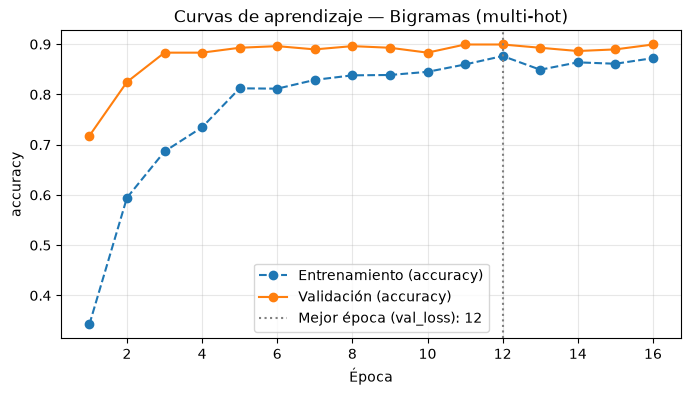

In [10]:
keras.utils.set_random_seed(SEED)
entradas = keras.Input(shape=(vec_bi.vocabulary_size(),), name="multi_hot")
x = layers.Dense(16, activation="relu")(entradas)
x = layers.Dropout(0.5)(x)
salidas = layers.Dense(N_CLASES, activation="softmax")(x)
modelo_bi = keras.Model(entradas, salidas, name="bigramas")
modelo_bi.summary()
hist_bi = entrenar_texto("Bigramas (multi-hot)", modelo_bi, train_bi, val_bi, test_bi, familia="Conjunto")

## 3. Modelo
**Embedding + LSTM bidireccional** (Bloque 5), con las **mismas reglas** que los bigramas: la misma división con semilla, el vocabulario de `vec_seq` construido solo con el entrenamiento, la misma función de entrenamiento y la prueba usada una sola vez.

| Capa | Salida |
|---|---|
| Entrada: índices | (lote, 600) |
| `Embedding(30,000, 64)` | (lote, 600, 64) |
| `Bidirectional(LSTM(32))` | (lote, 64) |
| `Dropout(0.5)` + `Dense(12, softmax)` | (lote, 12) |

Igual que en la práctica, sin máscara (`mask_zero=False`) cuando el motor es PyTorch, porque la máscara desactiva cuDNN y cada época tarda muchísimo. En Colab (TensorFlow) sí se usa.

Model: "bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ indices (InputLayer)            │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_palabras (Embedding)  │ (None, None, 64)       │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,945,612 (7.42 MB)

 Trainable params: 1,945,612 (7.42 MB)

 Non-trainable params: 0 (0.00 B)

Máscara: False


c:\Users\Edgar\Documents\Edgar\Ibero\Semestre 7\Aprendizaje automatico 3\ml_gpu_project\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/20


c:\Users\Edgar\Documents\Edgar\Ibero\Semestre 7\Aprendizaje automatico 3\ml_gpu_project\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:1076: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1412.)
  outputs, h_n, c_n = torch._VF.lstm(


45/45 - 1s - 15ms/step - accuracy: 0.1068 - loss: 2.4739 - val_accuracy: 0.1591 - val_loss: 2.4500
Epoch 2/20
45/45 - 0s - 6ms/step - accuracy: 0.1522 - loss: 2.4296 - val_accuracy: 0.1818 - val_loss: 2.4081
Epoch 3/20
45/45 - 0s - 6ms/step - accuracy: 0.1934 - loss: 2.3642 - val_accuracy: 0.1364 - val_loss: 2.4274
Epoch 4/20
45/45 - 0s - 7ms/step - accuracy: 0.2549 - loss: 2.2054 - val_accuracy: 0.2597 - val_loss: 2.2139
Epoch 5/20
45/45 - 0s - 6ms/step - accuracy: 0.3073 - loss: 1.9991 - val_accuracy: 0.2727 - val_loss: 2.0872
Epoch 6/20
45/45 - 0s - 6ms/step - accuracy: 0.3582 - loss: 1.8561 - val_accuracy: 0.4026 - val_loss: 1.8623
Epoch 7/20
45/45 - 0s - 6ms/step - accuracy: 0.4141 - loss: 1.6869 - val_accuracy: 0.4286 - val_loss: 1.7781
Epoch 8/20
45/45 - 0s - 6ms/step - accuracy: 0.4770 - loss: 1.5479 - val_accuracy: 0.4416 - val_loss: 1.7436
Epoch 9/20
45/45 - 0s - 6ms/step - accuracy: 0.5056 - loss: 1.4248 - val_accuracy: 0.5455 - val_loss: 1.5226
Epoch 10/20
45/45 - 0s - 6ms/

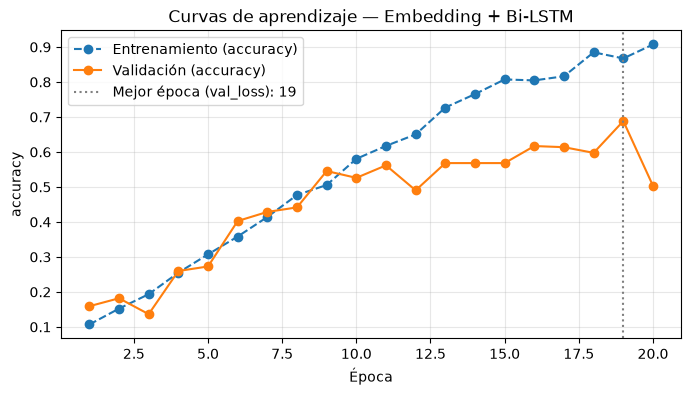

In [11]:
usar_mascara = keras.backend.backend() == "tensorflow"

keras.utils.set_random_seed(SEED)
entradas = keras.Input(shape=(None,), dtype="int64", name="indices")
x = layers.Embedding(vec_seq.vocabulary_size(), 64, mask_zero=usar_mascara, name="embedding_palabras")(entradas)
x = layers.Bidirectional(layers.LSTM(32))(x)
x = layers.Dropout(0.5)(x)
salidas = layers.Dense(N_CLASES, activation="softmax")(x)
modelo_seq = keras.Model(entradas, salidas, name="bilstm")
modelo_seq.summary()
print(f"Máscara: {usar_mascara}")
hist_seq = entrenar_texto("Embedding + Bi-LSTM", modelo_seq, train_seq, val_seq, test_seq, familia="Secuencia")

## 4. Resultados
Exactitud de **prueba** de los dos modelos (más la exactitud de validación, el F1 macro, que pesa igual a las 12 clases, el tamaño y el tiempo).

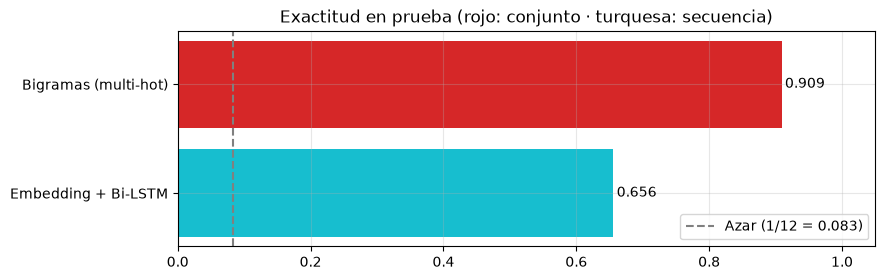

In [12]:
tabla = pd.DataFrame(resultados_dict).T.sort_values("Exactitud prueba")
plt.figure(figsize=(9, 2.8))
plt.barh(tabla.index, tabla["Exactitud prueba"].astype(float),
         color=["tab:red" if f == "Conjunto" else "tab:cyan" for f in tabla["Familia"]])
for i, v in enumerate(tabla["Exactitud prueba"].astype(float)):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.axvline(1 / N_CLASES, color="gray", linestyle="--", label=f"Azar (1/{N_CLASES} = {1 / N_CLASES:.3f})")
plt.xlim(0, 1.05)
plt.title("Exactitud en prueba (rojo: conjunto · turquesa: secuencia)")
plt.legend(loc="lower right")
plt.show()

In [13]:
resultados = pd.DataFrame(resultados_dict).T
for c in ["Exactitud val", "Exactitud prueba", "F1 macro prueba", "Seg/época"]:
    resultados[c] = resultados[c].astype(float).round(3)
for c in ["Parámetros", "Épocas"]:
    resultados[c] = resultados[c].astype(int)
resultados

,Familia,Exactitud val,Exactitud prueba,F1 macro prueba,Parámetros,Épocas,Seg/época
Bigramas (multi-hot),Conjunto,0.899,0.909,0.911,480220,16,0.389
Embedding + Bi-LSTM,Secuencia,0.688,0.656,0.657,1945612,20,0.339


## 5. Conclusión
### 5.1 ¿Se cumplió la regla del cociente?

In [14]:
ganador = resultados["Exactitud prueba"].idxmax()
familia_ganadora = resultados.loc[ganador, "Familia"]
prediccion_regla = "Conjunto" if cociente < 1500 else "Secuencia"
diferencia = resultados.loc["Bigramas (multi-hot)", "Exactitud prueba"] - resultados.loc["Embedding + Bi-LSTM", "Exactitud prueba"]
print(f"Cociente: {cociente:.1f} → la regla predice: {prediccion_regla}")
print(f"Ganador en prueba: {ganador} ({familia_ganadora})")
print(f"Diferencia (bigramas − Bi-LSTM): {diferencia * 100:+.1f} puntos de exactitud")
print("→ La regla", "SE CUMPLIÓ" if familia_ganadora == prediccion_regla else "NO se cumplió")

Cociente: 2.6 → la regla predice: Conjunto
Ganador en prueba: Bigramas (multi-hot) (Conjunto)
Diferencia (bigramas − Bi-LSTM): +25.3 puntos de exactitud
→ La regla SE CUMPLIÓ


### 5.2 ¿Dónde se equivoca el mejor modelo?
Matriz de confusión del mejor modelo en prueba, su reporte por clase y sus errores, empezando por los que cometió **con más seguridad**.

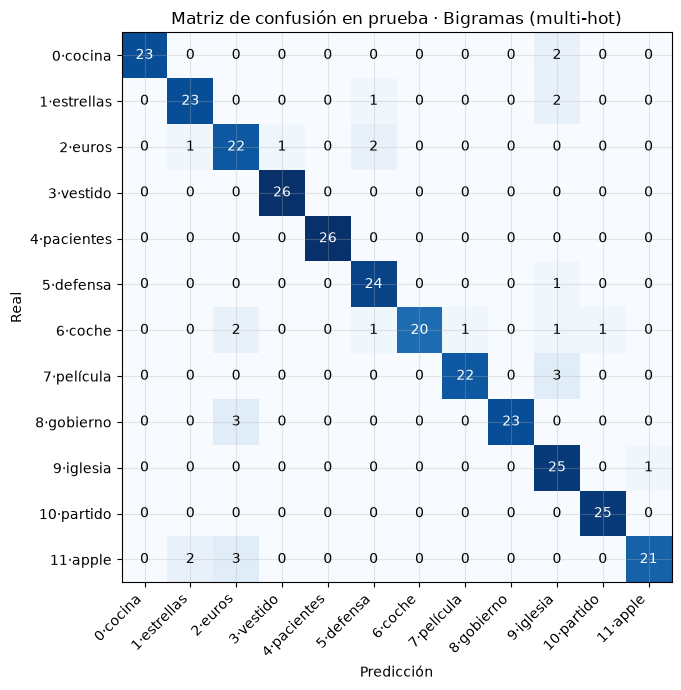

              precision    recall  f1-score   support

    0·cocina      1.000     0.920     0.958        25
 1·estrellas      0.885     0.885     0.885        26
     2·euros      0.733     0.846     0.786        26
   3·vestido      0.963     1.000     0.981        26
 4·pacientes      1.000     1.000     1.000        26
   5·defensa      0.857     0.960     0.906        25
     6·coche      1.000     0.769     0.870        26
  7·película      0.957     0.880     0.917        25
  8·gobierno      1.000     0.885     0.939        26
   9·iglesia      0.735     0.962     0.833        26
  10·partido      0.962     1.000     0.980        25
    11·apple      0.955     0.808     0.875        26

    accuracy                          0.909       308
   macro avg      0.920     0.909     0.911       308
weighted avg      0.920     0.909     0.910       308



In [15]:
probs_mejor = predicciones[ganador]
pred_mejor = probs_mejor.argmax(axis=1)
nombres_lista = [NOMBRES[k] for k in CLASES]

M_conf = confusion_matrix(y_test, pred_mejor, labels=CLASES)
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.imshow(M_conf, cmap="Blues")
ax.set_xticks(range(N_CLASES), nombres_lista, rotation=45, ha="right")
ax.set_yticks(range(N_CLASES), nombres_lista)
for i in range(N_CLASES):
    for j in range(N_CLASES):
        ax.text(j, i, M_conf[i, j], ha="center", va="center", color="white" if M_conf[i, j] > M_conf.max() / 2 else "black")
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión en prueba · {ganador}")
plt.tight_layout()
plt.show()

print(classification_report(y_test, pred_mejor, labels=CLASES, target_names=nombres_lista, digits=3, zero_division=0))

In [16]:
errores_idx = np.where(pred_mejor != y_test)[0]
errores = pd.DataFrame({
    "Real": [NOMBRES[y_test[i]] for i in errores_idx],
    "Predicción": [NOMBRES[pred_mejor[i]] for i in errores_idx],
    "P(predicción)": probs_mejor[errores_idx, pred_mejor[errores_idx]].round(2),
    "P(real)": probs_mejor[errores_idx, y_test[errores_idx]].round(2),
    "Inicio de la noticia": [x_test[i][:260].replace("\n", " ") + "..." for i in errores_idx],
}, index=errores_idx).sort_values("P(predicción)", ascending=False)
print(f"{ganador}: {len(errores)} errores de {len(y_test)} noticias de prueba")
print("\nConfusiones más frecuentes (real → predicción):")
print(errores.groupby(["Real", "Predicción"]).size().sort_values(ascending=False).head(6).to_string())
errores.head(8)

Bigramas (multi-hot): 28 errores de 308 noticias de prueba

Confusiones más frecuentes (real → predicción):
Real         Predicción 
11·apple     2·euros        3
7·película   9·iglesia      3
8·gobierno   2·euros        3
0·cocina     9·iglesia      2
11·apple     1·estrellas    2
1·estrellas  9·iglesia      2


,Real,Predicción,P(predicción),P(real),Inicio de la noticia
307,11·apple,2·euros,0.99,0.01,"En 2017 Roger Guasch encajó un golpe duro, de los más duros de su vida, en realidad: a su madre le diagnosticaron Alzheimer. La noticia llegó acompañada de ..."
285,6·coche,2·euros,0.95,0.02,Claudia PachecoEnlace copiadoEstas son las nuevas medidas que implementará el Gobierno en 2024 para cumplir con los objetivos de Bruselas para obtener un nu...
265,8·gobierno,2·euros,0.93,0.01,El Gobierno andaluz ha encontrado el filón para seguir haciendo crecer su economía desde uno de los sectores en auge como es la producción de energías renov...
76,11·apple,1·estrellas,0.90,0.04,"Antes de morir desintegrándose en la atmósfera de Saturno, la sonda Cassini tuvo ocasión de sobrevolar más de 100 veces Titán, la mayor de sus lunas. Gracia..."
46,6·coche,10·partido,0.83,0.02,"La climatología obliga a los organizadores a retrasar, en lo posible, la decisión sobre el programa horario y los trazados en donde competir.Las AndbankGSer..."
104,6·coche,2·euros,0.81,0.03,"Nueva legislatura y nuevas normas que se van fijando ya para los próximos años. En este sentido, la Ley de Movilidad Sostenible era una deuda que el Gobiern..."
70,11·apple,1·estrellas,0.75,0.02,"Hacia la década de 1970, en plena Guerra Fría, la URSS decidió dejar claro su poderío naval encargando los submarinos más grandes de la historia. Los bautiz..."
235,5·defensa,9·iglesia,0.72,0.07,"Al monumento a la Legión que se colocó en Madrid desde septiembre de 2022 junto al Cuartel General del Estado Mayor de la Defensa, le pegaron hace unos días..."


### 5.3 Conclusión
**Sí se cumplió la regla del cociente.** Me salió un cociente de 2.6 (1,432 noticias / 547 palabras de mediana), muy por debajo de 1,500, y tal como predije ganaron los bigramas, y por mucho: **90.9 % de exactitud en prueba contra 65.6 %** de la Bi-LSTM (+25.3 puntos). Además, la bolsa de bigramas tiene 4 veces menos parámetros. La Bi-LSTM sí aprendió algo (está muy arriba del 8.3 % del azar), pero con ~120 noticias por clase no le alcanzan los datos para aprovechar el orden. Se ve en sus curvas: la exactitud de entrenamiento sube hasta 90 % mientras la de validación brinca entre 50 % y 69 %. Llegó a las 20 épocas todavía mejorando un poco, así que con más épocas quizá subiría algo, pero no creo que alcance a los bigramas.

**Errores del mejor modelo (bigramas):** falló 28 de 308 noticias. Revisando los que falló con más seguridad, veo tres tipos de error:

1. **Noticias que mezclan temas.** La clase de economía (*2·euros*) se "come" noticias de otras clases que hablan de dinero o del gobierno. Por ejemplo, la #285 sobre nuevas medidas del Gobierno para cumplir con Bruselas (era *coche*, dijo *euros* con 0.95), la #104 sobre la Ley de Movilidad Sostenible (era *coche*, dijo *euros*) y la #265 sobre la economía andaluza y las energías renovables (era *gobierno*, dijo *euros*). Tiene sentido: el modelo solo ve palabras como "Gobierno", "millones" o "ley" y no entiende de qué trata realmente la noticia.
2. **Clases que se parecen mucho: ciencia contra tecnología.** La #76, sobre la sonda Cassini y Titán, y la #70, sobre los submarinos soviéticos, estaban etiquetadas como *tecnología* y el modelo dijo *ciencia/espacio*. Honestamente, yo también las habría puesto en ciencia, así que aquí el problema está más en la etiqueta que en el modelo.
3. **Palabras que engañan.** La #235, sobre un monumento a la Legión (era *defensa*), la mandó a *iglesia*, seguramente por palabras como "monumento" o por el vocabulario histórico. *9·iglesia* es la clase con peor precisión (0.735): atrae noticias que hablan de historia o de tradiciones. La #307 (era *tecnología*, dijo *economía* con 0.99) empieza contando la historia del Alzheimer de una madre, que no se parece a ninguna clase. Probablemente es una startup, pero el tema principal no se nota en las palabras.

En resumen: los bigramas son muy buenos cuando el tema está en las palabras, y fallan cuando una noticia toca dos temas o cuando la etiqueta del dataset es discutible. Para mejorar habría que darle más contexto al modelo, por ejemplo con un Transformer preentrenado como BETO, que ya entiende el idioma sin necesitar miles de ejemplos.